In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import transforms, models
from torchvision.datasets import EuroSAT
from torch.utils.data import random_split, DataLoader, Dataset
from sklearn.metrics import classification_report, confusion_matrix

In [16]:
SEED = 42
torch.manual_seed(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = '/content/drive/MyDrive/eurosat_data'        # persists across sessions
CKPT_DIR = '/content/drive/MyDrive/eurosat_checkpoints'

import os
os.makedirs(CKPT_DIR, exist_ok=True)


BATCH_SIZE = 32
NUM_CLASSES = 10
class_names = ['AnnualCrop', 'Forest', 'HerbVeg', 'Highway', 'Industrial',
               'Pasture', 'PermCrop', 'Residential', 'River', 'SeaLake']


Using device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
full_dataset = EuroSAT(root=DATA_ROOT, download=True)  # re-download clean

train_size = int(0.8 * len(full_dataset))
val_size = int(0.1 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)  # reproducible split
)


In [18]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])



In [19]:
class TransformedSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        image = self.transform(image)
        return image, label


In [20]:
train_set = TransformedSubset(train_subset, train_transform)
val_set = TransformedSubset(val_subset, eval_transform)
test_set = TransformedSubset(test_subset, eval_transform)


In [21]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)


Building the model

In [22]:
model = models.resnet50(weights='IMAGENET1K_V2')

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

def run_training(model, optimizer, num_epochs, checkpoint_path,
                  patience=3, history=None):
    """
    Trains `model` for up to `num_epochs`, saving the best checkpoint by
    validation accuracy, and stopping early if val accuracy plateaus.
    """
    if history is None:
        history = {'train_loss': [], 'val_acc': []}

    best_val_acc = 0.0
    epochs_no_improve = 0

    for epoch in range(num_epochs):
        # --- train ---
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_train_loss = running_loss / len(train_loader)

        # --- validate ---
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_accuracy = correct / total
        history['train_loss'].append(avg_train_loss)
        history['val_acc'].append(val_accuracy)

        print(f'Epoch {epoch+1}/{num_epochs} | '
              f'Loss: {avg_train_loss:.4f} | Val Accuracy: {val_accuracy:.4f}')

        # --- checkpoint + early stopping ---
        if val_accuracy > best_val_acc:
            best_val_acc = val_accuracy
            epochs_no_improve = 0
            torch.save(model.state_dict(), checkpoint_path)
            print(f'  -> New best model saved (val_acc={best_val_acc:.4f})')
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f'  -> Early stopping: no improvement for {patience} epochs')
                break

    return history, best_val_acc




Train only the final layer

In [23]:
phase1_ckpt = os.path.join(CKPT_DIR, 'best_model_phase1.pth')

optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
history, best_val_acc = run_training(
    model, optimizer, num_epochs=10,
    checkpoint_path=phase1_ckpt, patience=3
)

# Load the best weights from phase 1 before fine-tuning
model.load_state_dict(torch.load(phase1_ckpt, map_location=device))

KeyboardInterrupt: 

Fine tune (Phase 2)


In [ ]:
for param in model.parameters():
    param.requires_grad = True

finetune_ckpt = os.path.join(CKPT_DIR, 'best_model_finetuned.pth')

finetune_optimizer = optim.Adam(model.parameters(), lr=0.0001)
history, best_val_acc = run_training(
    model, finetune_optimizer, num_epochs=10,
    checkpoint_path=finetune_ckpt, patience=3, history=history
)

Plot Learning Curves

In [1]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(history['train_loss'], label='Train Loss', color='tab:red')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color='tab:red')

ax2 = ax1.twinx()
ax2.plot(history['val_acc'], label='Val Accuracy', color='tab:blue')
ax2.set_ylabel('Validation Accuracy', color='tab:blue')

plt.title('Training Loss and Validation Accuracy')
fig.tight_layout()
plt.savefig('learning_curves.png')
plt.show()

NameError: name 'plt' is not defined

In [ ]:
model.load_state_dict(torch.load(finetune_ckpt, map_location=device))
model.eval()


final eval

In [24]:
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = np.mean(np.array(all_preds) == np.array(all_labels))
print(f'\nFinal Test Accuracy: {test_accuracy:.4f}\n')

print(classification_report(all_labels, all_preds, target_names=class_names))



Final Test Accuracy: 0.8041

              precision    recall  f1-score   support

  AnnualCrop       0.86      0.93      0.89       300
      Forest       0.84      0.89      0.86       297
     HerbVeg       0.78      0.80      0.79       302
     Highway       0.71      0.53      0.61       269
  Industrial       0.76      0.88      0.82       257
     Pasture       0.82      0.78      0.80       187
    PermCrop       0.78      0.68      0.73       254
 Residential       0.85      0.89      0.87       314
       River       0.66      0.68      0.67       245
     SeaLake       0.92      0.94      0.93       275

    accuracy                           0.80      2700
   macro avg       0.80      0.80      0.80      2700
weighted avg       0.80      0.80      0.80      2700



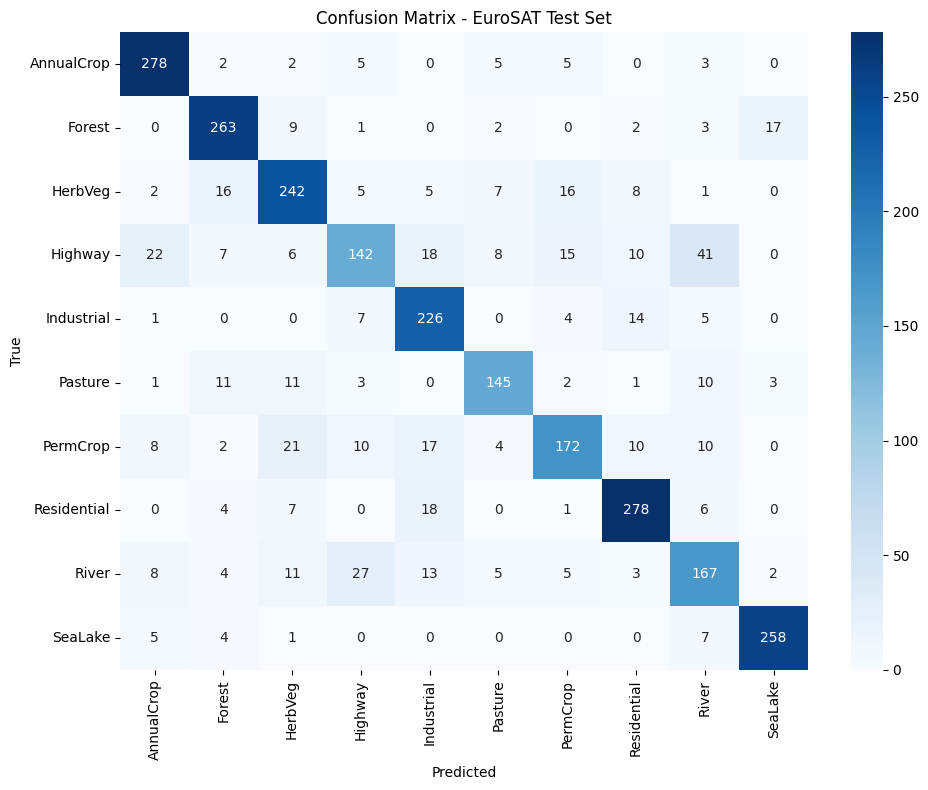

In [25]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - EuroSAT Test Set')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()